In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Semilla fija para reproducibilidad
SEED = 42
np.random.seed(SEED)

# Estilo de gráficas 
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Rutas del proyecto 
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "wdbc.data"
FIGURES_DIR = PROJECT_ROOT / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Librerías cargadas correctamente")
print("Ruta del dataset:", DATA_PATH)

Librerías cargadas correctamente
Ruta del dataset: C:\Users\fjuan\Desktop\Data Science 2026B\Proyecto\data\raw\wdbc.data


In [3]:
caracteristicas_base = [
    "radius", "texture", "perimeter", "area", "smoothness",
    "compactness", "concavity", "concave_points", "symmetry", "fractal_dimension"
]

columnas_features = [
    *[f"{c}_mean" for c in caracteristicas_base],
    *[f"{c}_se" for c in caracteristicas_base],
    *[f"{c}_worst" for c in caracteristicas_base],
]

columnas_completas = ["id", "diagnosis", *columnas_features]

df = pd.read_csv(DATA_PATH, header=None, names=columnas_completas)
df["target"] = df["diagnosis"].map({"B": 0, "M": 1}).astype(int)

print("Filas y columnas originales:", df.shape)
print("Total de valores nulos:", df.isnull().sum().sum())
print("\nConteo de clases (0 = Benigno, 1 = Maligno):")
print(df["target"].value_counts())
print("\nProporción de clases:")
print(df["target"].value_counts(normalize=True).round(3))

df.head()

Filas y columnas originales: (569, 33)
Total de valores nulos: 0

Conteo de clases (0 = Benigno, 1 = Maligno):
target
0    357
1    212
Name: count, dtype: int64

Proporción de clases:
target
0    0.627
1    0.373
Name: proportion, dtype: float64


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst,target
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


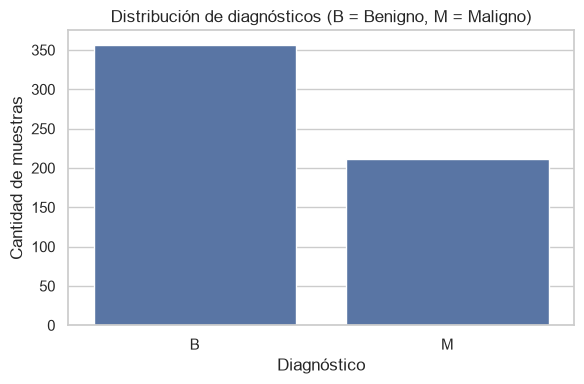

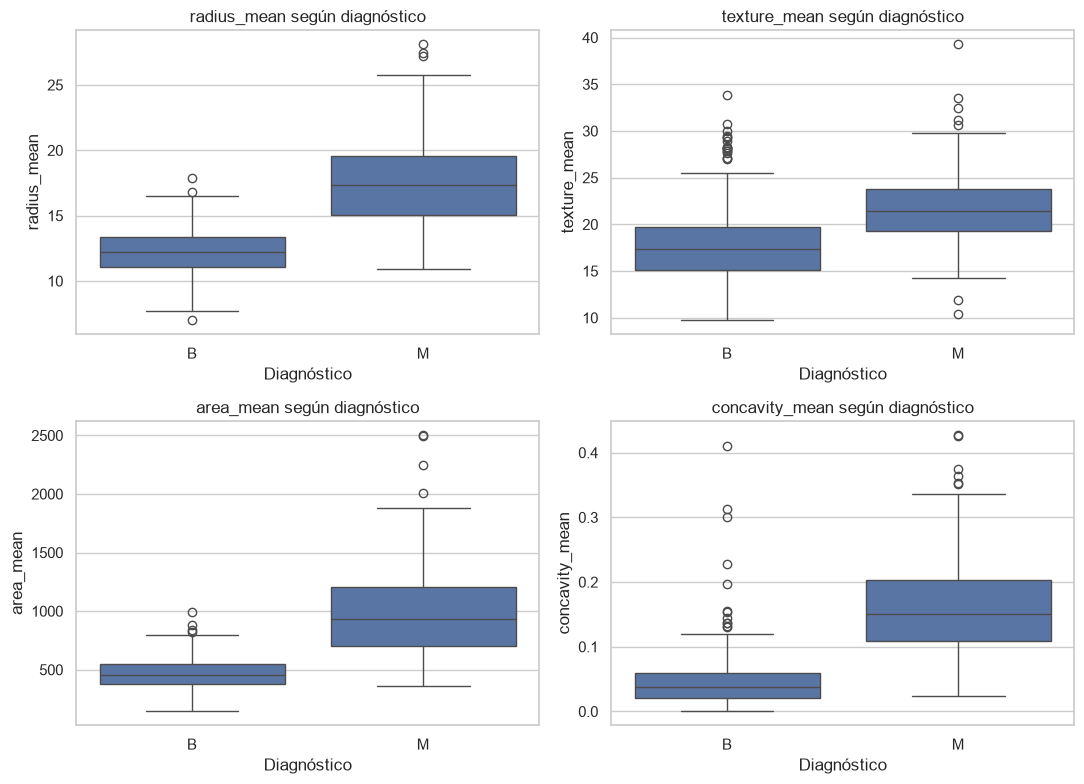

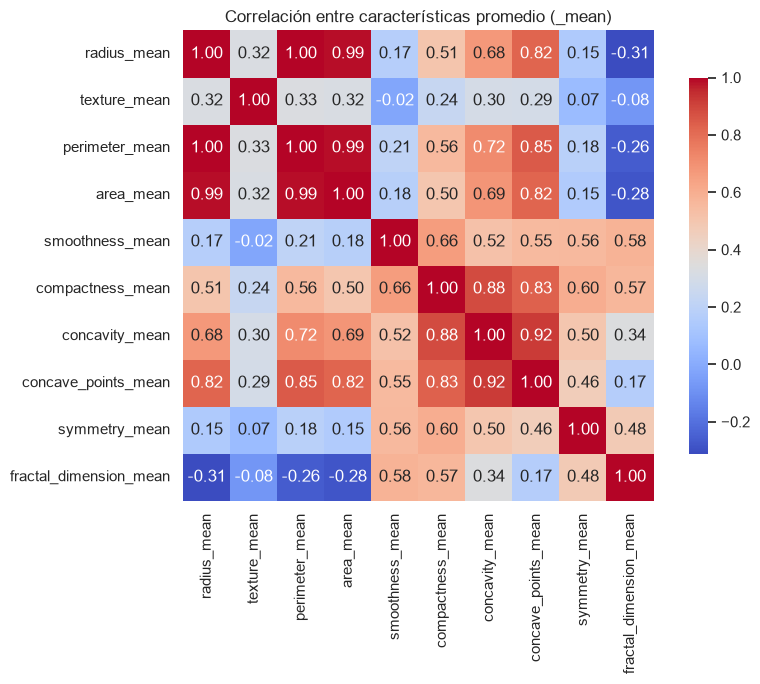

In [4]:
# Gráfica 1 ( Proporción de clases (Benigno vs Maligno) )
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x="diagnosis", order=["B", "M"])
plt.title("Distribución de diagnósticos (B = Benigno, M = Maligno)")
plt.xlabel("Diagnóstico")
plt.ylabel("Cantidad de muestras")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig1_distribucion_clases.png", dpi=300)
plt.show()

# Gráfica 2 ( Boxplot comparativo de variables clave por diagnóstico )
vars_clave = ["radius_mean", "texture_mean", "area_mean", "concavity_mean"]
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.ravel(), vars_clave):
    sns.boxplot(data=df, x="diagnosis", y=col, order=["B", "M"], ax=ax)
    ax.set_title(f"{col} según diagnóstico")
    ax.set_xlabel("Diagnóstico")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig2_boxplots_variables.png", dpi=300)
plt.show()

# Gráfica 3 ( Mapa de correlación de las 10 variables "_mean" )
cols_mean = [f"{c}_mean" for c in caracteristicas_base]
plt.figure(figsize=(9, 7))
corr_mean = df[cols_mean].corr()
sns.heatmap(corr_mean, annot=True, fmt=".2f", cmap="coolwarm", square=True, cbar_kws={"shrink": 0.8})
plt.title("Correlación entre características promedio (_mean)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig3_correlacion_mean.png", dpi=300)
plt.show()

In [5]:
# Eliminamos 'id' porque es un identificador sin valor predictivo
X = df[columnas_features].copy()
y = df["target"].copy()

# 1) Separación de prueba (15%) 
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size=0.15,
    random_state=SEED,
    stratify=y
)

# 2) Separación de la validación 
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.1765,
    random_state=SEED,
    stratify=y_temp
)

# 3) Escalador de ajustando (sin fuga de datos)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Tamaño X_train:", X_train.shape)
print("Tamaño X_val:  ", X_val.shape)
print("Tamaño X_test: ", X_test.shape)
print("Proporción malignos (1) -> Train:", round(y_train.mean(), 3),
      "| Val:", round(y_val.mean(), 3),
      "| Test:", round(y_test.mean(), 3))

Tamaño X_train: (397, 30)
Tamaño X_val:   (86, 30)
Tamaño X_test:  (86, 30)
Proporción malignos (1) -> Train: 0.373 | Val: 0.372 | Test: 0.372


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# 1. Baseline (Regresion Logistica)

espacio_lr = {
    "C": [0.01, 0.1, 1.0, 10.0],
    "solver": ["lbfgs"],
    "max_iter": [1000]
}
grid_lr = GridSearchCV(
    LogisticRegression(random_state=SEED),
    param_grid=espacio_lr,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)
grid_lr.fit(X_train_scaled, y_train)
print("Mejor LR:", grid_lr.best_params_, "| Mejor F1 (CV):", round(grid_lr.best_score_, 4))

# 2. Clasificador Bayesiano
espacio_nb = {
    "var_smoothing": np.logspace(-11, -7, 5)
}
grid_nb = GridSearchCV(
    GaussianNB(),
    param_grid=espacio_nb,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)
grid_nb.fit(X_train_scaled, y_train)
print("Mejor GaussianNB:", grid_nb.best_params_, "| Mejor F1 (CV):", round(grid_nb.best_score_, 4))

# 3. SVM ( kernel lineal y RBF ajustando )
espacio_svm = [
    {"kernel": ["linear"], "C": [0.01, 0.1, 1.0, 10.0, 100.0]},
    {"kernel": ["rbf"], "C": [0.1, 1.0, 10.0, 100.0], "gamma": ["scale", 0.01, 0.1, 1.0]}
]
grid_svm = GridSearchCV(
    SVC(probability=True, random_state=SEED),
    param_grid=espacio_svm,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)
grid_svm.fit(X_train_scaled, y_train)
print("Mejor SVM:", grid_svm.best_params_, "| Mejor F1 (CV):", round(grid_svm.best_score_, 4))

# 4. Red Neuronal
espacio_mlp = {
    "hidden_layer_sizes": [(32,), (64, 32)],
    "activation": ["relu"],
    "alpha": [0.0001, 0.001, 0.01],
    "early_stopping": [True],
    "validation_fraction": [0.15],
    "max_iter": [500]
}
grid_mlp = GridSearchCV(
    MLPClassifier(random_state=SEED),
    param_grid=espacio_mlp,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)
grid_mlp.fit(X_train_scaled, y_train)
print("Mejor MLP:", grid_mlp.best_params_, "| Mejor F1 (CV):", round(grid_mlp.best_score_, 4))

Mejor LR: {'C': 1.0, 'max_iter': 1000, 'solver': 'lbfgs'} | Mejor F1 (CV): 0.959
Mejor GaussianNB: {'var_smoothing': np.float64(1e-11)} | Mejor F1 (CV): 0.9081


C:\Users\fjuan\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Mejor SVM: {'C': 10.0, 'gamma': 0.01, 'kernel': 'rbf'} | Mejor F1 (CV): 0.9656
Mejor MLP: {'activation': 'relu', 'alpha': 0.0001, 'early_stopping': True, 'hidden_layer_sizes': (32,), 'max_iter': 500, 'validation_fraction': 0.15} | Mejor F1 (CV): 0.9154


In [7]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score,
)
from sklearn.model_selection import cross_val_score

modelos_mejores = {
    "Regresion Logistica (Baseline)": grid_lr.best_estimator_,
    "GaussianNB": grid_nb.best_estimator_,
    "SVM (RBF)": grid_svm.best_estimator_,
    "MLP": grid_mlp.best_estimator_,
}

resultados = []

for nombre, modelo in modelos_mejores.items():
    # Desviacion estandar de F1 entre los 5 folds de entrenamiento
    scores_cv = cross_val_score(modelo, X_train_scaled, y_train, cv=cv, scoring="f1", n_jobs=-1)

    # Predicciones en el conjunto de prueba
    y_pred = modelo.predict(X_test_scaled)

    # Puntaje continuo para ROC-AUC y Precision-Recall
    if hasattr(modelo, "predict_proba"):
        y_scores = modelo.predict_proba(X_test_scaled)[:, 1]
    else:
        y_scores = modelo.decision_function(X_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_scores)
    pr_auc = average_precision_score(y_test, y_scores)

    resultados.append({
        "Modelo": nombre,
        "F1_CV_media": round(scores_cv.mean(), 4),
        "F1_CV_std": round(scores_cv.std(), 4),
        "Accuracy_test": round(acc, 4),
        "Precision_test": round(prec, 4),
        "Recall_test": round(rec, 4),
        "F1_test": round(f1, 4),
        "ROC_AUC": round(roc_auc, 4),
        "PR_AUC": round(pr_auc, 4),
    })

    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()
    print(f"=== {nombre} ===")
    print(f"Matriz de confusion -> TN: {tn}, FP: {fp}, FN: {fn}, TP: {tp}")
    print(cm, "\n")

df_resultados = pd.DataFrame(resultados)
print("Tabla comparativa de modelos:")
display(df_resultados)

=== Regresion Logistica (Baseline) ===
Matriz de confusion -> TN: 54, FP: 0, FN: 1, TP: 31
[[54  0]
 [ 1 31]] 

=== GaussianNB ===
Matriz de confusion -> TN: 53, FP: 1, FN: 3, TP: 29
[[53  1]
 [ 3 29]] 

=== SVM (RBF) ===
Matriz de confusion -> TN: 54, FP: 0, FN: 1, TP: 31
[[54  0]
 [ 1 31]] 

=== MLP ===
Matriz de confusion -> TN: 52, FP: 2, FN: 0, TP: 32
[[52  2]
 [ 0 32]] 

Tabla comparativa de modelos:


,Modelo,F1_CV_media,F1_CV_std,Accuracy_test,Precision_test,Recall_test,F1_test,ROC_AUC,PR_AUC
0,Regresion Logistica (Baseline),0.9590,0.0254,0.9884,1.0000,0.9688,0.9841,0.9983,0.9973
1,GaussianNB,0.9081,0.0489,0.9535,0.9667,0.9062,0.9355,0.9954,0.9926
2,SVM (RBF),0.9656,0.0217,0.9884,1.0000,0.9688,0.9841,1.0000,1.0000
3,MLP,0.9154,0.0422,0.9767,0.9412,1.0000,0.9697,0.9971,0.9951


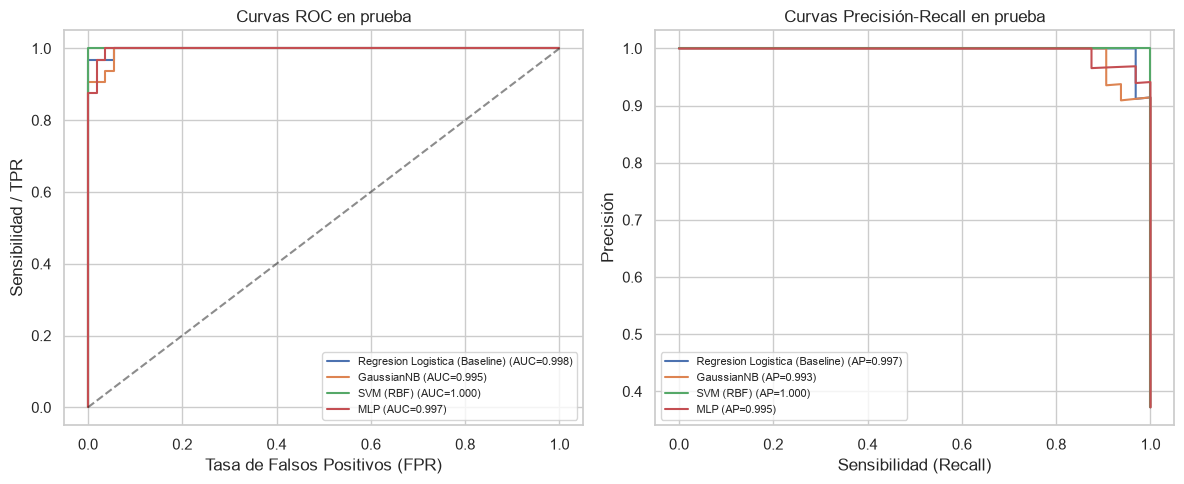

Imagen guardada en: C:\Users\fjuan\Desktop\Data Science 2026B\Proyecto\figures\fig4_curvas_roc_pr.png


In [8]:
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score,
)

modelos_mejores = {
    "Regresion Logistica (Baseline)": grid_lr.best_estimator_,
    "GaussianNB": grid_nb.best_estimator_,
    "SVM (RBF)": grid_svm.best_estimator_,
    "MLP": grid_mlp.best_estimator_,
}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for nombre, modelo in modelos_mejores.items():
    if hasattr(modelo, "predict_proba"):
        y_scores = modelo.predict_proba(X_test_scaled)[:, 1]
    else:
        y_scores = modelo.decision_function(X_test_scaled)

    fpr, tpr, _ = roc_curve(y_test, y_scores)
    auc_val = roc_auc_score(y_test, y_scores)
    axes[0].plot(fpr, tpr, label=f"{nombre} (AUC={auc_val:.3f})")

    prec_c, rec_c, _ = precision_recall_curve(y_test, y_scores)
    ap_val = average_precision_score(y_test, y_scores)
    axes[1].plot(rec_c, prec_c, label=f"{nombre} (AP={ap_val:.3f})")

axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[0].set_title("Curvas ROC en prueba")
axes[0].set_xlabel("Tasa de Falsos Positivos (FPR)")
axes[0].set_ylabel("Sensibilidad / TPR")
axes[0].legend(fontsize=8)

axes[1].set_title("Curvas Precisión-Recall en prueba")
axes[1].set_xlabel("Sensibilidad (Recall)")
axes[1].set_ylabel("Precisión")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig4_curvas_roc_pr.png", dpi=300)
plt.show()

print("Imagen guardada en:", FIGURES_DIR / "fig4_curvas_roc_pr.png")

In [9]:
OUTPUTS_DIR = Path(".") / "outputs"
OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)

# 1. Guardar tabla comparativa de modelos
df_resultados.to_csv(OUTPUTS_DIR / "resultados_modelos.csv", index=False, encoding="utf-8-sig")
df_resultados.to_excel(OUTPUTS_DIR / "resultados_modelos.xlsx", index=False)
print("Archivos de resultados guardados en:", OUTPUTS_DIR)

# 2. Guardar matrices de confusion en CSV
filas_cm = []
for nombre, modelo in modelos_mejores.items():
    y_pred = modelo.predict(X_test_scaled)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    filas_cm.append({
        "Modelo": nombre,
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    })

df_cm = pd.DataFrame(filas_cm)
df_cm.to_csv(OUTPUTS_DIR / "matrices_confusion.csv", index=False, encoding="utf-8-sig")
print("Archivo guardado:", OUTPUTS_DIR / "matrices_confusion.csv")

# 3. Guardar casos de error en prueba en CSV
if "df_errores" in globals() and "errores_mask" in globals():
    df_errores[errores_mask].to_csv(OUTPUTS_DIR / "errores_prueba.csv", index=False, encoding="utf-8-sig")
    print("Archivo guardado:", OUTPUTS_DIR / "errores_prueba.csv")

Archivos de resultados guardados en: outputs
Archivo guardado: outputs\matrices_confusion.csv
